# Beneficiary Data — Exploratory Data Analysis

Standalone EDA on `data/raw/beneficiary_raw.csv`, run **before** any cleaning or joining (see `01_data_loading_joining.ipynb` / `02_cleaning.ipynb`). This table has a different grain than the claims tables — **one row per patient**, not per claim — and no diagnosis/procedure/duration columns. Its content is demographics, Medicare coverage, chronic condition flags, and annual reimbursement totals, so the EDA here focuses on those instead of mirroring `inpatient_eda.ipynb` / `outpatient_eda.ipynb` structurally.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

from src.data_loader import RAW_DATA_DIR

beneficiary = pd.read_csv(RAW_DATA_DIR / 'beneficiary_raw.csv')

for col in ['DOB', 'DOD']:
    beneficiary[col] = pd.to_datetime(beneficiary[col], errors='coerce')

beneficiary.shape

(138556, 25)

## Shape & Columns

In [2]:
beneficiary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138556 entries, 0 to 138555
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   BeneID                           138556 non-null  object        
 1   DOB                              138556 non-null  datetime64[ns]
 2   DOD                              1421 non-null    datetime64[ns]
 3   Gender                           138556 non-null  int64         
 4   Race                             138556 non-null  int64         
 5   RenalDiseaseIndicator            138556 non-null  object        
 6   State                            138556 non-null  int64         
 7   County                           138556 non-null  int64         
 8   NoOfMonths_PartACov              138556 non-null  int64         
 9   NoOfMonths_PartBCov              138556 non-null  int64         
 10  ChronicCond_Alzheimer            138556 non-

In [3]:
beneficiary.head()

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
0,BENE11001,1943-01-01,NaT,1,1,0,39,230,12,12,1,2,1,2,2,1,1,1,2,1,1,36000,3204,60,70
1,BENE11002,1936-09-01,NaT,2,1,0,39,280,12,12,2,2,2,2,2,2,2,2,2,2,2,0,0,30,50
2,BENE11003,1936-08-01,NaT,1,1,0,52,590,12,12,1,2,2,2,2,2,2,1,2,2,2,0,0,90,40
3,BENE11004,1922-07-01,NaT,1,1,0,39,270,12,12,1,1,2,2,2,2,1,1,1,1,2,0,0,1810,760
4,BENE11005,1935-09-01,NaT,1,1,0,24,680,12,12,2,2,2,2,1,2,1,2,2,2,2,0,0,1790,1200


## Missing Values

Per `data/raw/raw_data.md`, `DOD` (date of death) missing is expected and means **the beneficiary is alive** — not a data quality issue. Everything else should be fully populated at this grain.

In [4]:
missing = pd.DataFrame({
    'n_missing': beneficiary.isna().sum(),
    'pct_missing': (beneficiary.isna().mean() * 100).round(2),
    'dtype': beneficiary.dtypes,
})
missing.sort_values('pct_missing', ascending=False)

,n_missing,pct_missing,dtype
DOD,137135,98.97,datetime64[ns]
BeneID,0,0.00,object
ChronicCond_Cancer,0,0.00,int64
OPAnnualReimbursementAmt,0,0.00,int64
IPAnnualDeductibleAmt,0,0.00,int64
IPAnnualReimbursementAmt,0,0.00,int64
ChronicCond_stroke,0,0.00,int64
ChronicCond_rheumatoidarthritis,0,0.00,int64
ChronicCond_Osteoporasis,0,0.00,int64
ChronicCond_IschemicHeart,0,0.00,int64


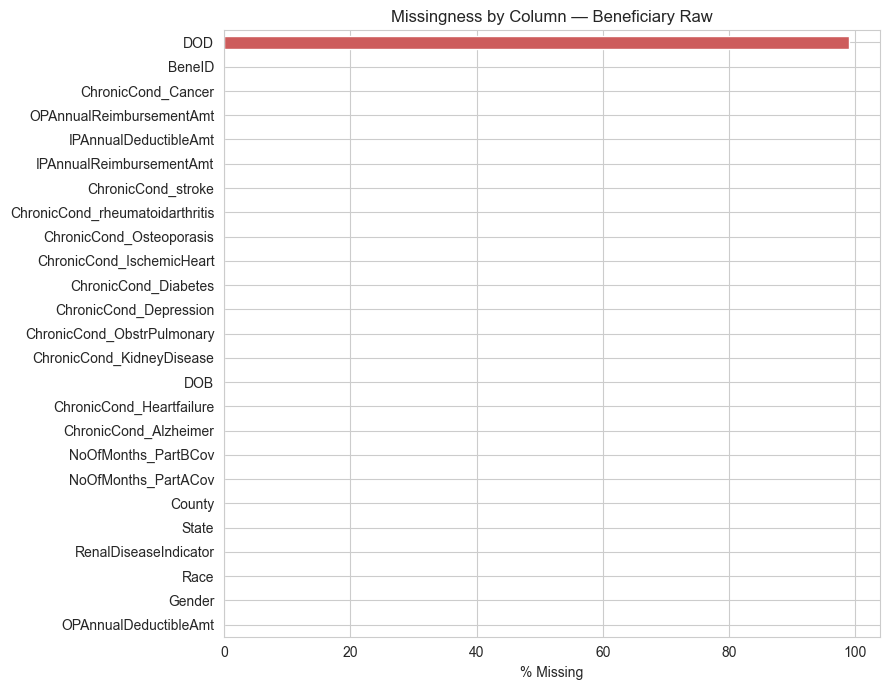

In [5]:
missing_pct = missing['pct_missing'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 7))
missing_pct.plot(kind='barh', ax=ax, color='indianred')
ax.invert_yaxis()
ax.set_xlabel('% Missing')
ax.set_title('Missingness by Column — Beneficiary Raw')
plt.tight_layout()
plt.show()

## Row-Level Integrity Checks

In [6]:
print('Total rows:', len(beneficiary))
print('Unique BeneID:', beneficiary['BeneID'].nunique())
print('Duplicate BeneID rows:', beneficiary['BeneID'].duplicated().sum())
print('Fully duplicated rows:', beneficiary.duplicated().sum())

Total rows: 138556
Unique BeneID: 138556
Duplicate BeneID rows: 0
Fully duplicated rows: 0


## Age & Mortality

`DOB` gives year/month/day of birth but no claim-time reference, so age here is computed **as of 2009-12-31** (the end of the claims period across both `inpatient_raw.csv` and `outpatient_raw.csv`) — a beneficiary-level snapshot age, distinct from the per-claim `AgeAtClaim` derived later in the pipeline.

In [7]:
reference_date = pd.Timestamp('2009-12-31')
beneficiary['IsDeceased'] = beneficiary['DOD'].notna().astype(int)
beneficiary['Age'] = ((reference_date - beneficiary['DOB']).dt.days / 365.25).round(1)

print('IsDeceased rate:', beneficiary['IsDeceased'].mean().round(4))
beneficiary['Age'].describe()

IsDeceased rate: 0.0103


count    138556.000000
mean         73.668875
std          12.727363
min          26.100000
25%          68.100000
50%          74.300000
75%          82.000000
max         101.000000
Name: Age, dtype: float64

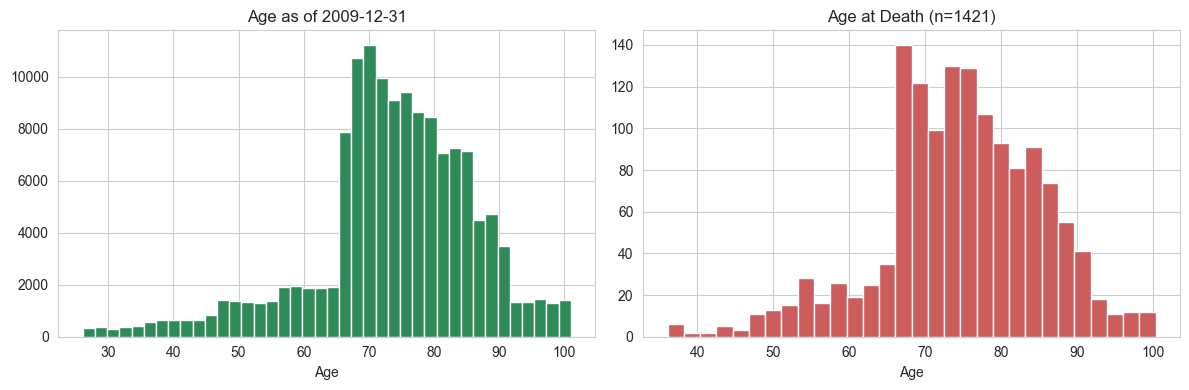

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(beneficiary['Age'], bins=40, color='seagreen')
axes[0].set_title('Age as of 2009-12-31')
axes[0].set_xlabel('Age')

deceased = beneficiary[beneficiary['IsDeceased'] == 1]
age_at_death = ((deceased['DOD'] - deceased['DOB']).dt.days / 365.25).round(1)
axes[1].hist(age_at_death, bins=30, color='indianred')
axes[1].set_title(f'Age at Death (n={len(deceased)})')
axes[1].set_xlabel('Age')
plt.tight_layout()
plt.show()

## Demographics: Gender & Race

In [9]:
print('Gender distribution:')
print(beneficiary['Gender'].value_counts(normalize=True).round(3))
print()
print('Race distribution:')
print(beneficiary['Race'].value_counts(normalize=True).round(3))

Gender distribution:
Gender
2    0.571
1    0.429
Name: proportion, dtype: float64

Race distribution:
Race
1    0.845
2    0.098
3    0.037
5    0.021
Name: proportion, dtype: float64


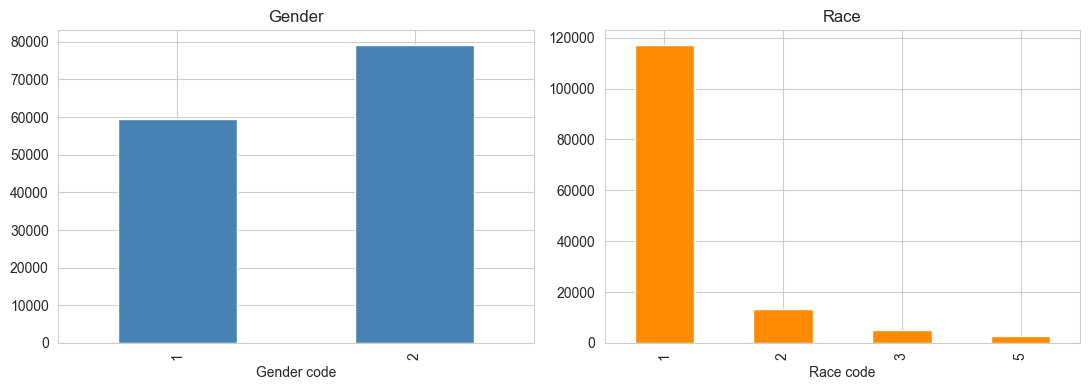

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
beneficiary['Gender'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Gender')
axes[0].set_xlabel('Gender code')

beneficiary['Race'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Race')
axes[1].set_xlabel('Race code')
plt.tight_layout()
plt.show()

## Geography: State & County

In [11]:
print('Unique states:', beneficiary['State'].nunique())
print('Unique counties:', beneficiary['County'].nunique())
print()
print('Top 10 states by beneficiary count:')
beneficiary['State'].value_counts().head(10)

Unique states: 52
Unique counties: 314

Top 10 states by beneficiary count:


State
5     12052
10     9771
45     8780
33     8443
39     6055
14     5923
36     5366
23     5293
34     4629
31     4124
Name: count, dtype: int64

## Medicare Coverage (Part A / Part B Months)

In [12]:
beneficiary[['NoOfMonths_PartACov', 'NoOfMonths_PartBCov']].describe()

,NoOfMonths_PartACov,NoOfMonths_PartBCov
count,138556.000000,138556.000000
mean,11.907727,11.910145
std,1.032332,0.936893
min,0.000000,0.000000
25%,12.000000,12.000000
50%,12.000000,12.000000
75%,12.000000,12.000000
max,12.000000,12.000000


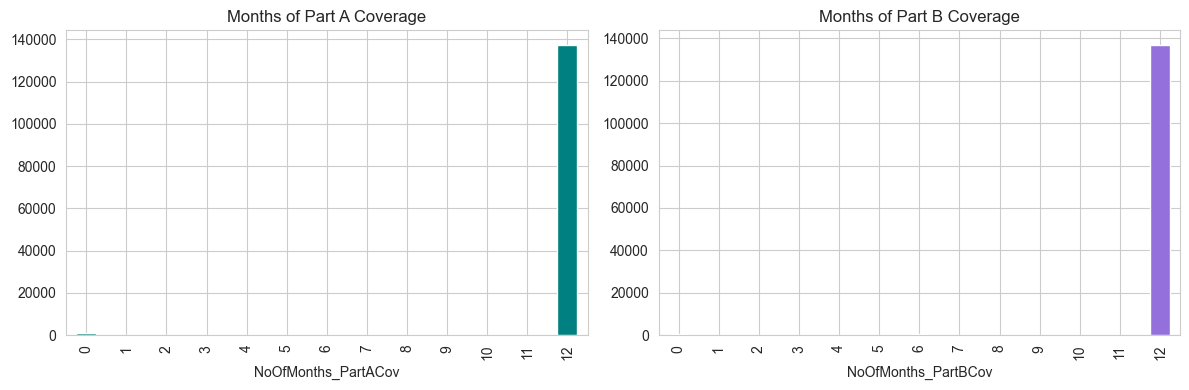

Share with full-year Part A AND Part B coverage: 98.2%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
beneficiary['NoOfMonths_PartACov'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='teal')
axes[0].set_title('Months of Part A Coverage')

beneficiary['NoOfMonths_PartBCov'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='mediumpurple')
axes[1].set_title('Months of Part B Coverage')
plt.tight_layout()
plt.show()

full_year_both = ((beneficiary['NoOfMonths_PartACov'] == 12) & (beneficiary['NoOfMonths_PartBCov'] == 12)).mean()
print(f'Share with full-year Part A AND Part B coverage: {full_year_both * 100:.1f}%')

## Chronic Conditions

Recoding each `ChronicCond_*` flag from `1`=Yes/`2`=No to `1`/`0`, plus `RenalDiseaseIndicator` from `Y`/`0` to `1`/`0`, matching the cleaning step's convention.

In [14]:
chronic_cols = [
    'ChronicCond_Alzheimer', 'ChronicCond_Heartfailure', 'ChronicCond_KidneyDisease',
    'ChronicCond_Cancer', 'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
    'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart', 'ChronicCond_Osteoporasis',
    'ChronicCond_rheumatoidarthritis', 'ChronicCond_stroke',
]

for col in chronic_cols:
    beneficiary[col] = beneficiary[col].map({1: 1, 2: 0})

beneficiary['RenalDiseaseIndicator'] = beneficiary['RenalDiseaseIndicator'].map({'Y': 1, '0': 0})

prevalence = beneficiary[chronic_cols + ['RenalDiseaseIndicator']].mean().sort_values(ascending=False)
prevalence

ChronicCond_IschemicHeart          0.675857
ChronicCond_Diabetes               0.601858
ChronicCond_Heartfailure           0.493678
ChronicCond_Depression             0.355524
ChronicCond_Alzheimer              0.332183
ChronicCond_KidneyDisease          0.312357
ChronicCond_Osteoporasis           0.274683
ChronicCond_rheumatoidarthritis    0.256820
ChronicCond_ObstrPulmonary         0.237153
RenalDiseaseIndicator              0.141300
ChronicCond_Cancer                 0.119959
ChronicCond_stroke                 0.079058
dtype: float64

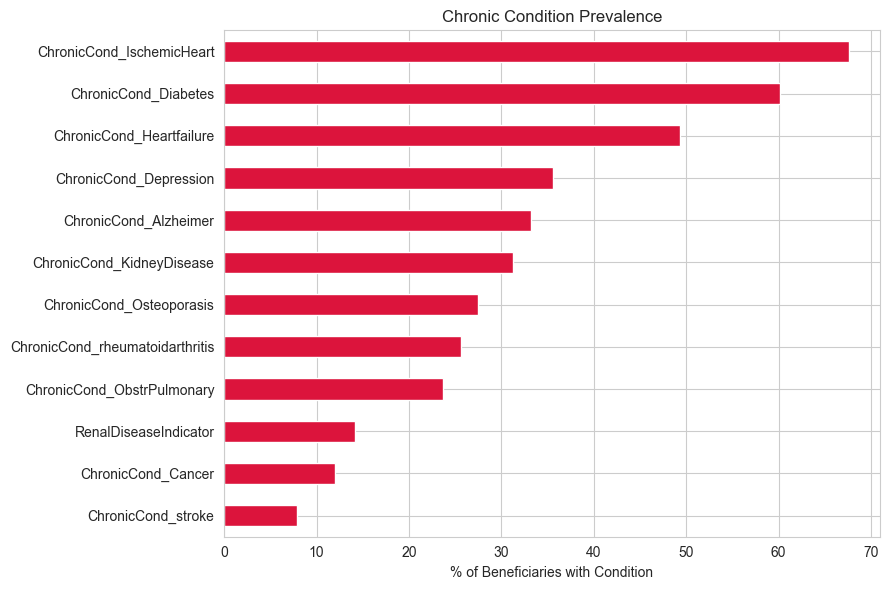

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))
(prevalence * 100).plot(kind='barh', ax=ax, color='crimson')
ax.invert_yaxis()
ax.set_xlabel('% of Beneficiaries with Condition')
ax.set_title('Chronic Condition Prevalence')
plt.tight_layout()
plt.show()

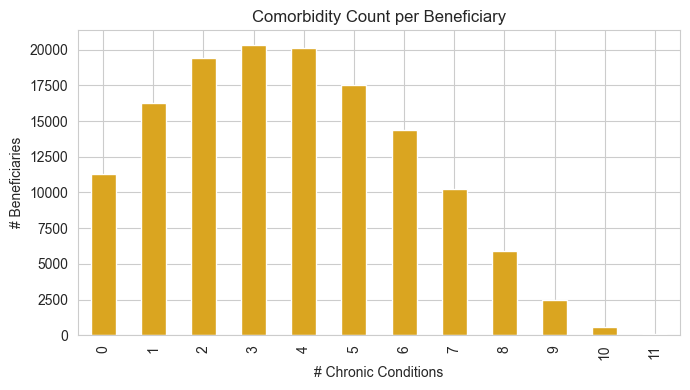

count    138556.000000
mean          3.739131
std           2.346638
min           0.000000
25%           2.000000
50%           4.000000
75%           5.000000
max          11.000000
Name: NumChronicConditions, dtype: float64

In [16]:
beneficiary['NumChronicConditions'] = beneficiary[chronic_cols].sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
beneficiary['NumChronicConditions'].value_counts().sort_index().plot(kind='bar', ax=ax, color='goldenrod')
ax.set_xlabel('# Chronic Conditions')
ax.set_ylabel('# Beneficiaries')
ax.set_title('Comorbidity Count per Beneficiary')
plt.tight_layout()
plt.show()

beneficiary['NumChronicConditions'].describe()

## Annual Reimbursement & Deductible Amounts (IP / OP)

In [17]:
amt_cols = ['IPAnnualReimbursementAmt', 'IPAnnualDeductibleAmt', 'OPAnnualReimbursementAmt', 'OPAnnualDeductibleAmt']
beneficiary[amt_cols].describe()

,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
count,138556.000000,138556.000000,138556.000000,138556.000000
mean,3660.346502,399.847296,1298.219348,377.718258
std,9568.621827,956.175202,2493.901134,645.530187
min,-8000.000000,0.000000,-70.000000,0.000000
25%,0.000000,0.000000,170.000000,40.000000
50%,0.000000,0.000000,570.000000,170.000000
75%,2280.000000,1068.000000,1500.000000,460.000000
max,161470.000000,38272.000000,102960.000000,13840.000000


In [18]:
for col in amt_cols:
    neg_count = (beneficiary[col] < 0).sum()
    if neg_count:
        print(f'{col}: {neg_count} negative rows, min={beneficiary[col].min()}')

IPAnnualReimbursementAmt: 15 negative rows, min=-8000
OPAnnualReimbursementAmt: 12 negative rows, min=-70


IPAnnualReimbursementAmt: 74.0% are zero
IPAnnualDeductibleAmt: 73.6% are zero
OPAnnualReimbursementAmt: 3.0% are zero
OPAnnualDeductibleAmt: 10.0% are zero


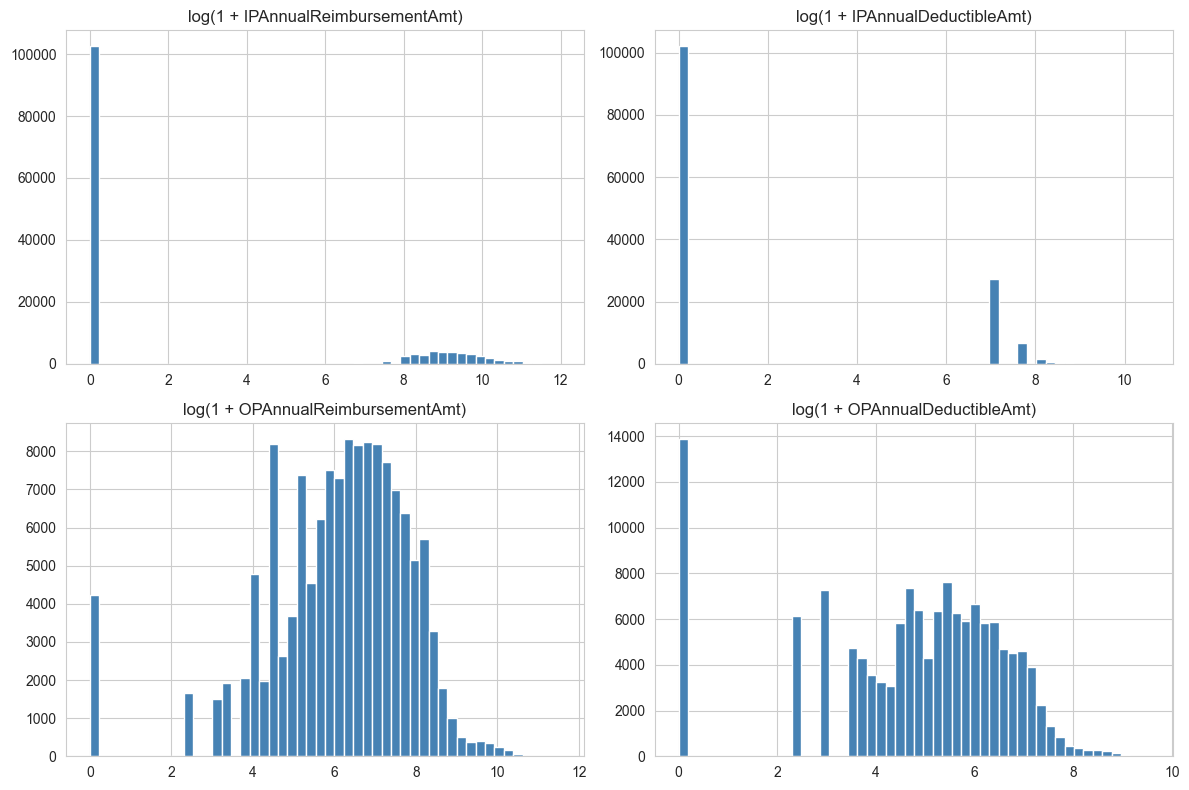

In [19]:
for col in amt_cols:
    zero_share = (beneficiary[col] == 0).mean() * 100
    print(f'{col}: {zero_share:.1f}% are zero')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, amt_cols):
    # clip the handful of negative values so log1p doesn't produce NaN
    ax.hist(np.log1p(beneficiary[col].clip(lower=0)), bins=50, color='steelblue')
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

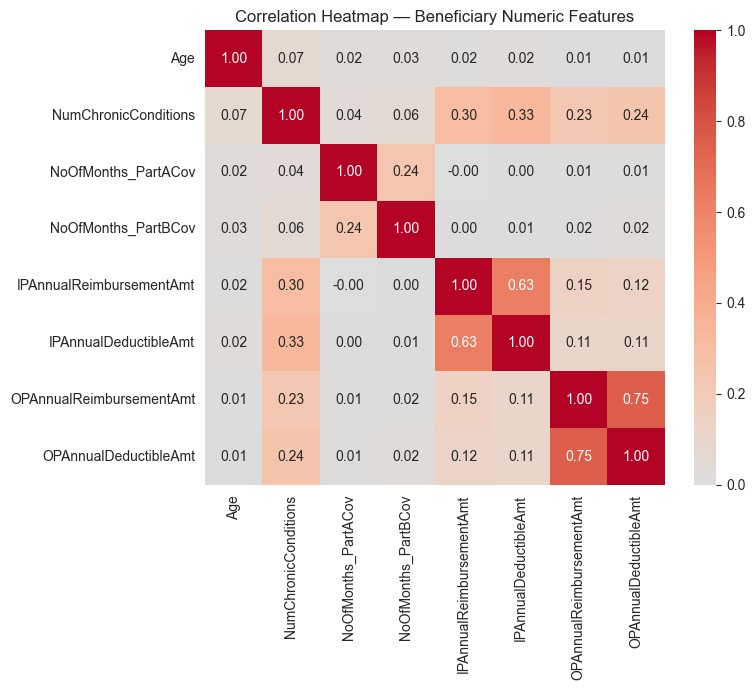

In [20]:
numeric_cols = ['Age', 'NumChronicConditions', 'NoOfMonths_PartACov', 'NoOfMonths_PartBCov'] + amt_cols
corr = beneficiary[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap — Beneficiary Numeric Features')
plt.tight_layout()
plt.show()

## Fraud Label Context

The beneficiary table has no `Provider` or fraud label of its own — it only connects to fraud via the claims tables. Here, each beneficiary's claims (inpatient + outpatient) are joined to `provider_labels.csv` to check whether beneficiaries who ever used a potentially-fraudulent provider look different demographically/clinically from those who didn't. This is EDA only, not part of the cleaning pipeline.

In [21]:
inpatient = pd.read_csv(RAW_DATA_DIR / 'inpatient_raw.csv', usecols=['BeneID', 'Provider'])
outpatient = pd.read_csv(RAW_DATA_DIR / 'outpatient_raw.csv', usecols=['BeneID', 'Provider'])
claims = pd.concat([inpatient, outpatient], ignore_index=True)

labels = pd.read_csv(RAW_DATA_DIR / 'provider_labels.csv')
labels['PotentialFraud'] = labels['PotentialFraud'].map({'Yes': 1, 'No': 0})

claims_labeled = claims.merge(labels, on='Provider', how='left')

bene_fraud_exposure = claims_labeled.groupby('BeneID').agg(
    NumClaims=('Provider', 'count'),
    NumProviders=('Provider', 'nunique'),
    FraudClaimShare=('PotentialFraud', 'mean'),
).reset_index()
bene_fraud_exposure['EverUsedFraudProvider'] = (bene_fraud_exposure['FraudClaimShare'] > 0).astype(int)

print('Beneficiaries with >=1 claim:', len(bene_fraud_exposure))
print('Share who ever used a potentially-fraudulent provider:',
      bene_fraud_exposure['EverUsedFraudProvider'].mean().round(3))

beneficiary_labeled = beneficiary.merge(bene_fraud_exposure, on='BeneID', how='left')
beneficiary_labeled[['NumClaims', 'NumProviders', 'FraudClaimShare', 'EverUsedFraudProvider']] = \
    beneficiary_labeled[['NumClaims', 'NumProviders', 'FraudClaimShare', 'EverUsedFraudProvider']].fillna(0)
beneficiary_labeled.shape

Beneficiaries with >=1 claim: 138556
Share who ever used a potentially-fraudulent provider: 0.606


(138556, 32)

In [22]:
beneficiary_labeled.groupby('EverUsedFraudProvider')[
    ['Age', 'NumChronicConditions', 'NumClaims', 'IPAnnualReimbursementAmt', 'OPAnnualReimbursementAmt']
].mean().round(2)

,Age,NumChronicConditions,NumClaims,IPAnnualReimbursementAmt,OPAnnualReimbursementAmt
EverUsedFraudProvider,,,,,
0,73.43,3.26,2.86,1961.64,938.46
1,73.83,4.05,4.79,4763.72,1531.90


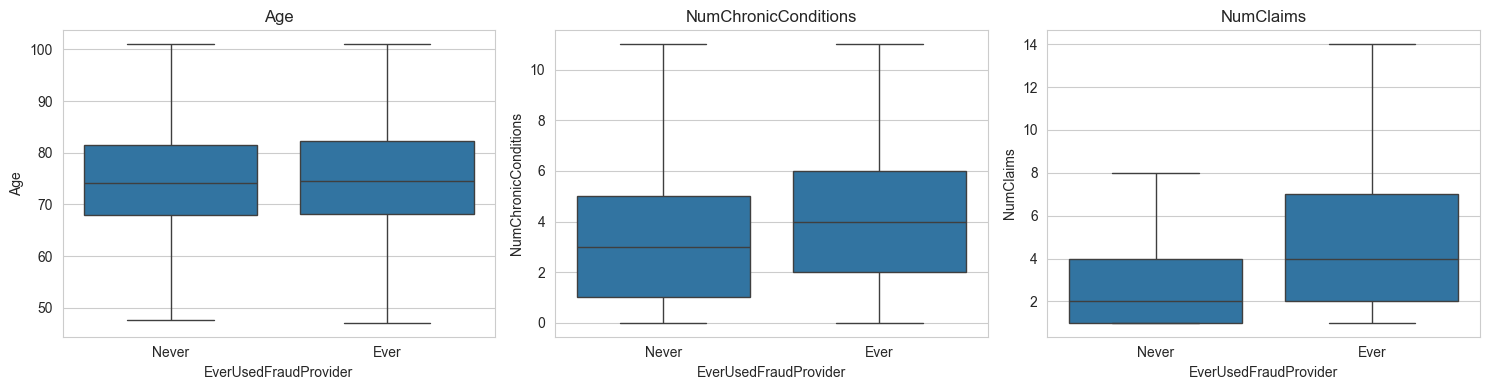

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age', 'NumChronicConditions', 'NumClaims']):
    sns.boxplot(data=beneficiary_labeled, x='EverUsedFraudProvider', y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Never', 'Ever'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Summary of Findings

**Shape & integrity**
- 138,556 beneficiaries, 25 columns, one row per `BeneID` with no duplicates — clean at the row level.
- `DOD` is 98.97% missing (137,135 of 138,556) — per the data dictionary this means **alive**, not missing data. Only 1,421 beneficiaries (1.03%) died during the observation window.
- Every other column is 100% populated.

**Age & mortality**
- Age as of 2009-12-31 ranges from 26.1 to 101, mean 73.7, median 74.3 — consistent with a Medicare population (65+ eligibility), with the under-65 tail likely reflecting disability-based Medicare eligibility rather than a data error.

**Demographics**
- Gender: 57.1% code `2`, 42.9% code `1` (raw codes, not decoded to male/female in this table).
- Race: heavily skewed — 84.5% code `1`, 9.8% code `2`, 3.7% code `3`, 2.1% code `5` (no code `4` observed).
- 52 unique states, 314 unique counties represented, both categorical (FIPS-style) rather than ordinal.

**Coverage**
- 98.2% of beneficiaries have full 12-month Part A **and** Part B coverage for the year — partial-year coverage is the exception, not the norm.

**Chronic conditions**
- Prevalence ranges from **67.6%** (ischemic heart disease) and **60.2%** (diabetes) down to **7.9%** (stroke) and **12.0%** (cancer). `RenalDiseaseIndicator` prevalence is 14.1%.
- Mean **3.74** chronic conditions per beneficiary (out of 11 tracked), median 4 — comorbidity is the norm in this population, useful as a single `NumChronicConditions` feature alongside the individual flags.

**Annual reimbursement (IP / OP)**
- `IPAnnualReimbursementAmt`: 74.0% are exactly $0 (no inpatient stay that year) — right-skewed with a long tail up to $161,470 for the minority who were hospitalized.
- `OPAnnualReimbursementAmt`: only 3.0% are $0 — almost everyone has *some* outpatient utilization, consistent with outpatient claims outnumbering inpatient ~13:1 in the claims tables.
- **Data quality flag**: 15 beneficiaries have a *negative* `IPAnnualReimbursementAmt` (as low as -$8,000) and 12 have a negative `OPAnnualReimbursementAmt` (as low as -$70). Small in count but should be clipped or investigated during cleaning — a negative reimbursement isn't a valid claim amount.

**Fraud exposure (via claims join, EDA only — not part of the cleaning pipeline)**
- 60.6% of beneficiaries had at least one claim tied to a potentially-fraudulent provider at some point in the year.
- Beneficiaries who ever used a fraud provider have **more chronic conditions** (4.05 vs. 3.26), **more claims** (4.79 vs. 2.86), and **much higher annual reimbursement** (IP: $4,764 vs. $1,962; OP: $1,532 vs. $938) than those who never did. This lines up with `03_eda_stats.ipynb`'s provider-level finding that fraud providers bill more and see higher claim volume — sicker, higher-utilization beneficiaries are simply more likely to cross paths with one.

**Implications for cleaning / feature engineering**
1. Recode `ChronicCond_*` (1/2 → 1/0) and `RenalDiseaseIndicator` (`Y`/`0` → 1/0) as already planned in the cleaning step — done here for the prevalence/correlation analysis.
2. Clip or flag the ~27 rows with negative `IPAnnualReimbursementAmt` / `OPAnnualReimbursementAmt` before using them as numeric features.
3. `NumChronicConditions` (sum of the 11 flags) is a compact, informative single feature — consider it alongside or instead of all 11 individual flags to reduce dimensionality.
4. `DOD`'s missingness should be converted to `IsDeceased` (done here), never imputed or dropped as "missing data."
5. Beneficiary-level utilization/comorbidity features (`NumChronicConditions`, `IPAnnualReimbursementAmt`, `OPAnnualReimbursementAmt`) correlate with fraud-provider exposure — worth carrying into provider-level aggregates (e.g. average patient comorbidity burden per provider) in `04_feature_engineering.ipynb`.